# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import SYSUCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [5]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/sysu_cd/train/",
}
dataset = SYSUCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 12000


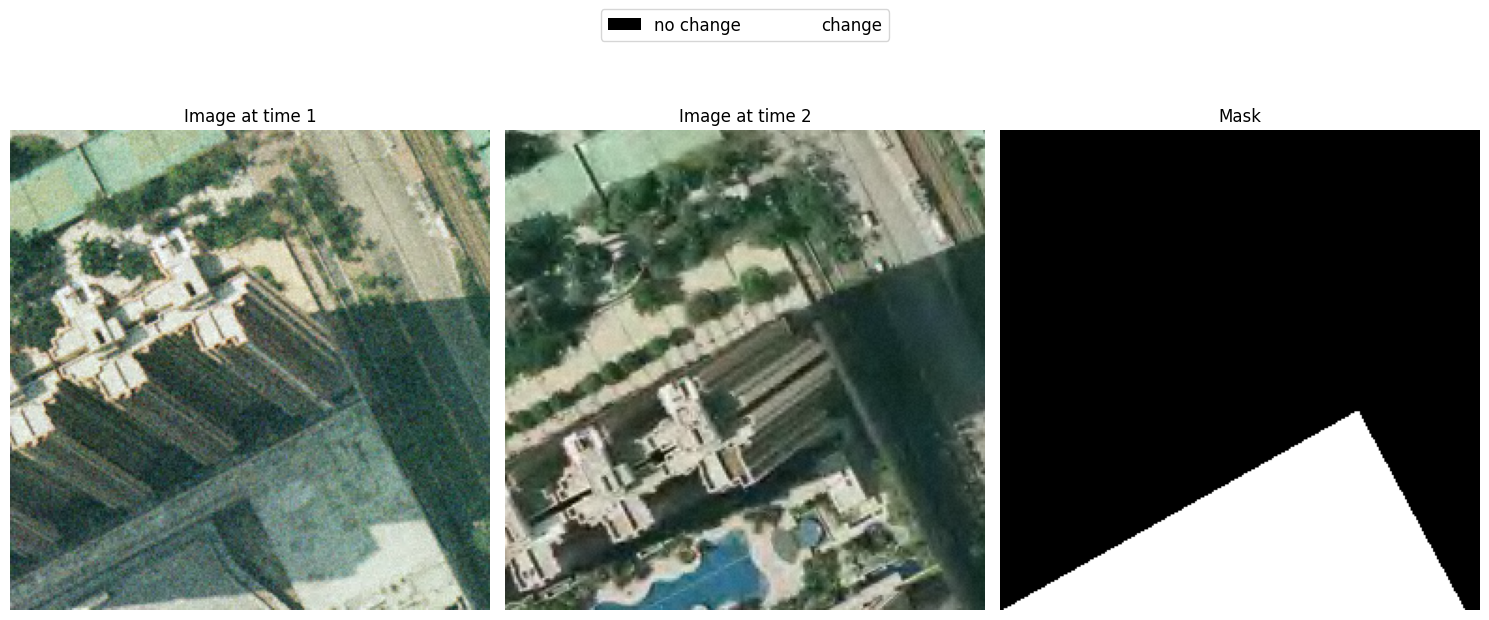

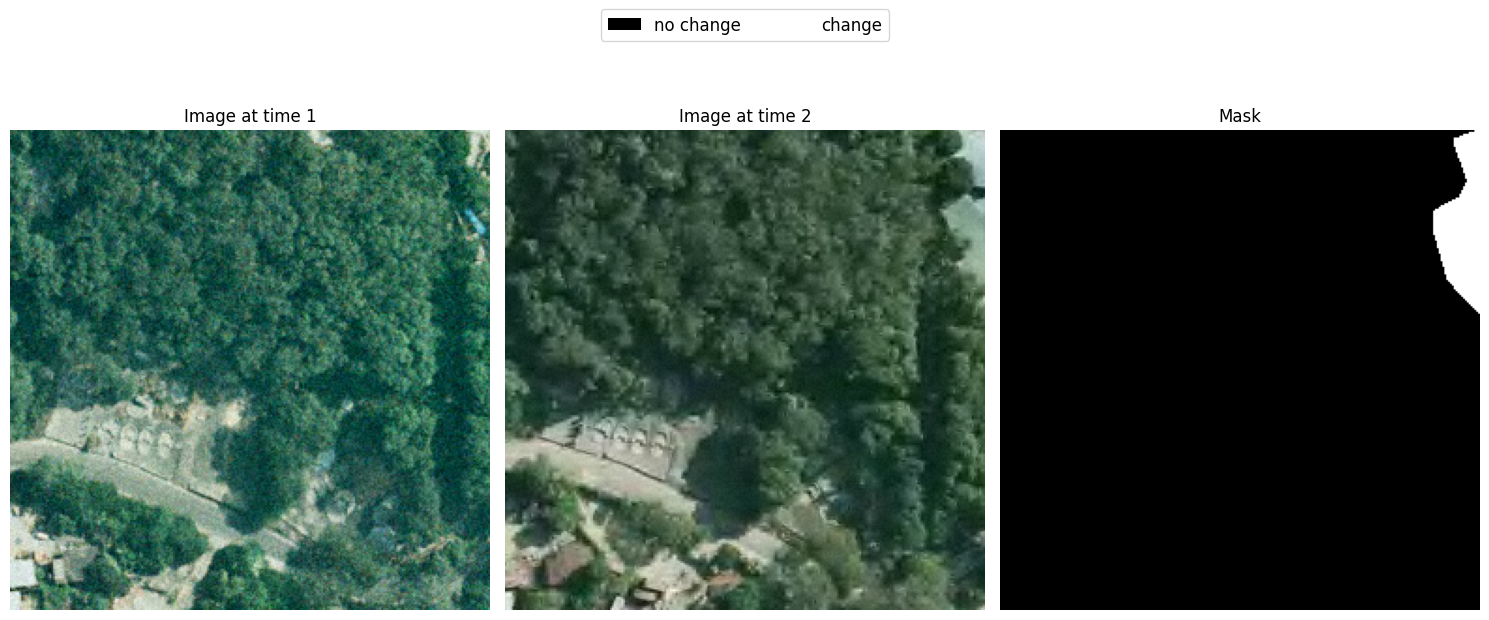

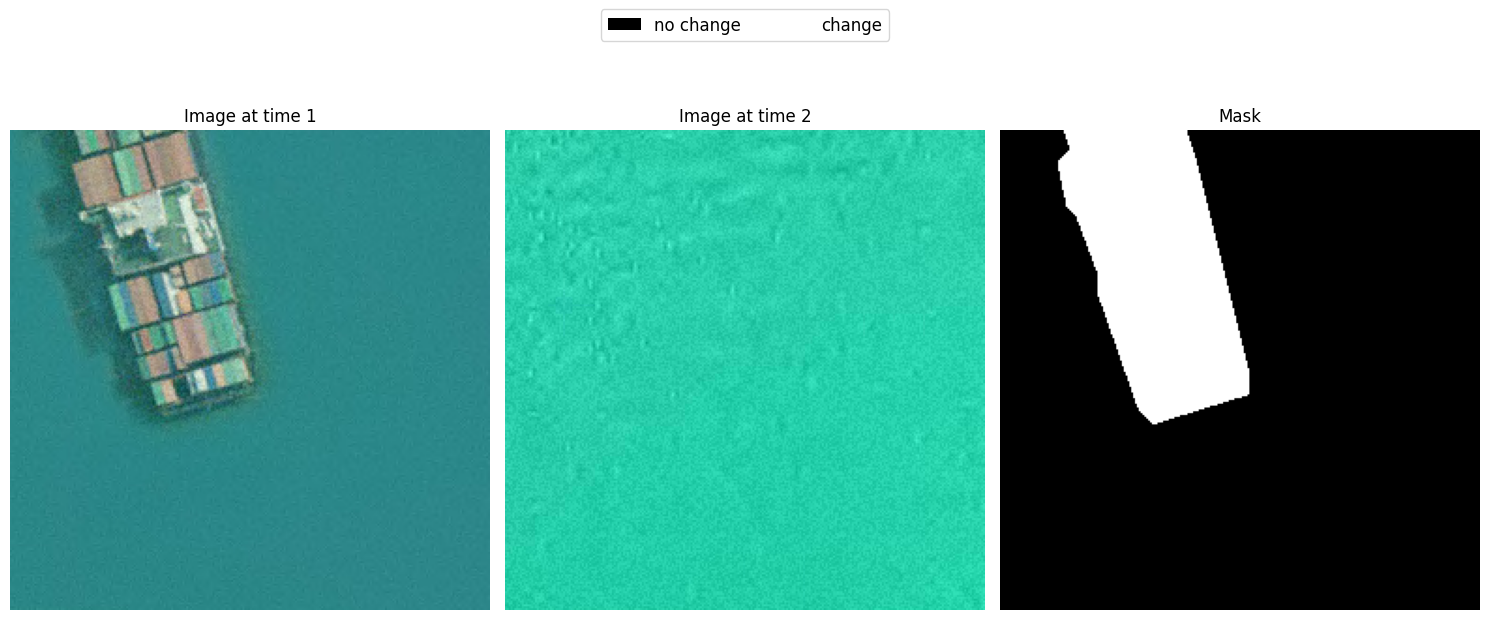

In [6]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [10]:
dataset.data_distribution_table()

,Number of pixels
no change,618598691.0
change,167833309.0


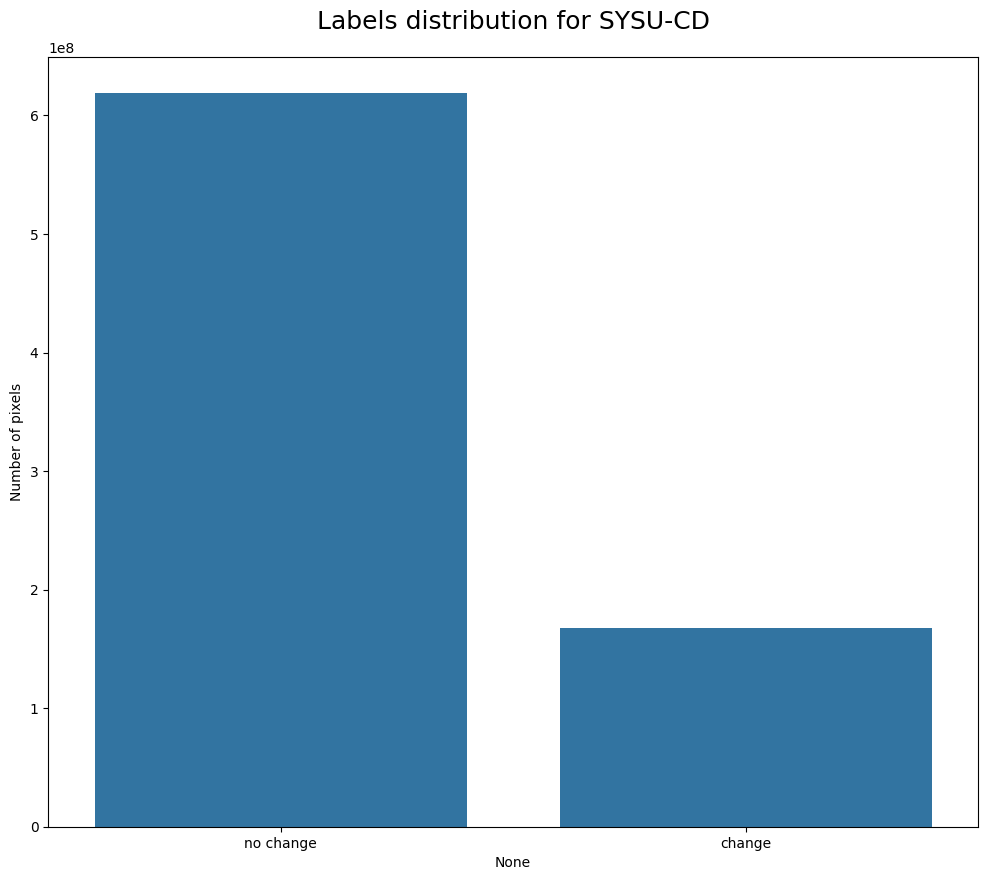

In [11]:
dataset.data_distribution_barchart();

## Load training and test data

In [7]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/sysu_cd/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SYSUCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/sysu_cd/val/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = SYSUCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(12000, 4000)

## Create the model

In [10]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/sysu_cd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [11]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-29 12:21:36,709 INFO Starting training.
training: 100%|██████████| 750/750 [06:37<00:00,  1.88it/s]
2026-01-29 12:28:14,668 INFO epoch: 1, loss:  0.22528
testing on train set: 100%|██████████| 750/750 [06:32<00:00,  1.91it/s]
2026-01-29 12:34:49,118 INFO Accuracy:0.7864318911234538, Accuracy per Class:[0.78620026 0.78666353], Precision Micro:0.7892724560678396, Precision Macro:0.6487713106383383, Precision Weighted:0.7302246325451988, Precision per Class:[0.7908796  0.50666302], Recall Micro:0.7815220476786295, Recall Macro:0.5016224388219666, Recall Weighted:0.7815220476786294, Recall per Class:[0.98995188 0.01329299], F1_score Micro:0.7853781313485388, F1_score Macro:0.4525976409407756, F1_score Weighted:0.6971676555655228, F1_score per Class:[0.87928898 0.0259063 ], IOU:0.6466029894723607, IOU mean:0.39885225168440425, IOU per Class:[0.78458137 0.01312314]
training: 100%|██████████| 750/750 [06:38<00:00,  1.88it/s]
2026-01-29 12:41:27,193 INFO epoch: 2, loss:  0.21427
testin

## Predictions

2026-01-29 14:40:18,449 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/sysu_cd/checkpoint.pth.tar
2026-01-29 14:40:18,801 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/sysu_cd/checkpoint.pth.tar at epoch 11


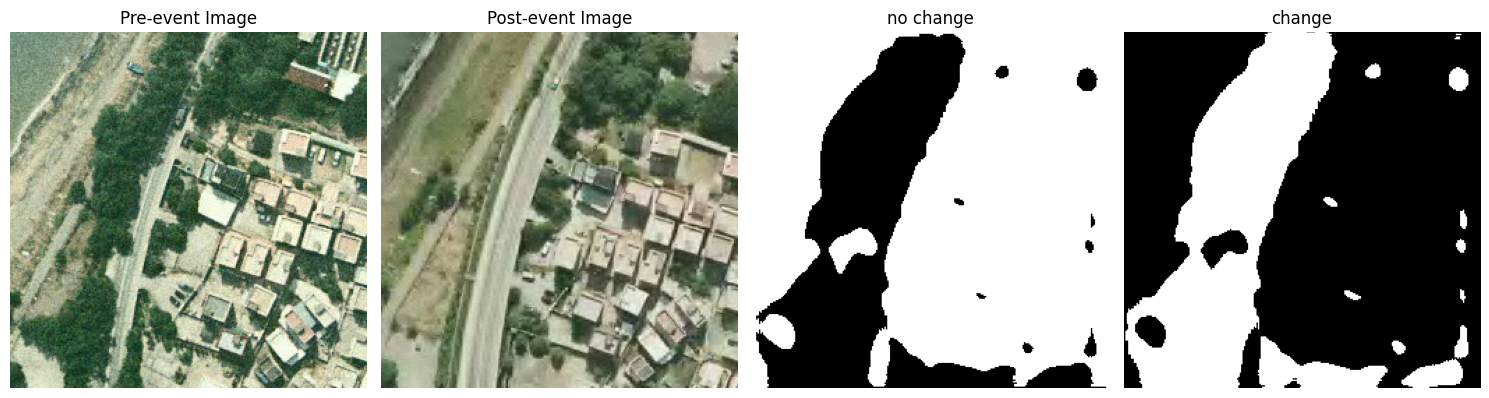

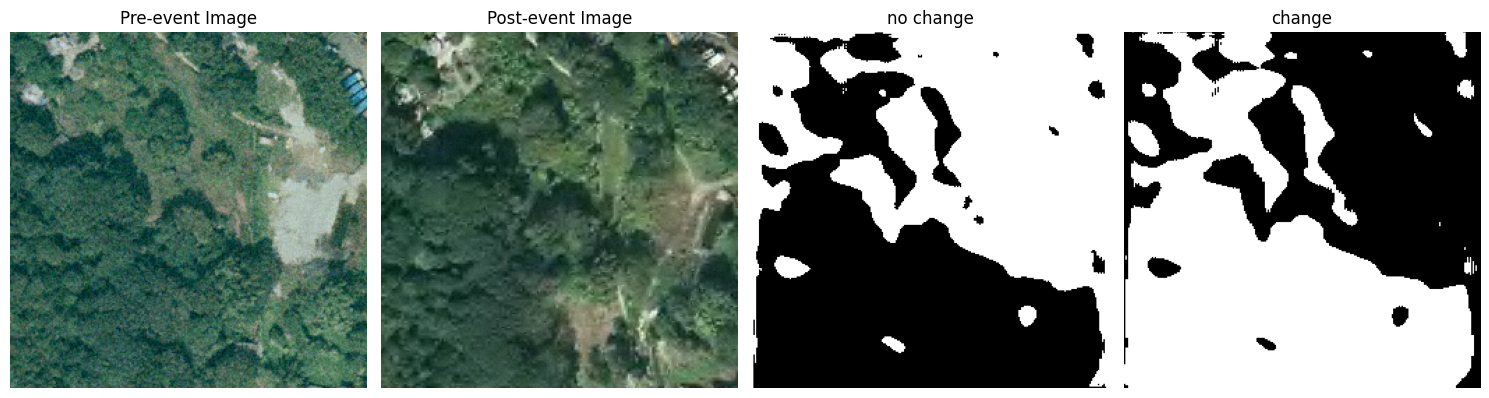

In [12]:
model_path = "/home/dragik/data/FAIR_EO/experiments/sysu_cd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/sysu_cd/test/time1/00001.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/sysu_cd/test/time2/00001.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/sysu_cd/test/time1/01180.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/sysu_cd/test/time2/01180.png")
fig = model.predict_masks(image1, image2, labels, transform)